 ## Practical Assistant Agent

---

## What you will build

A **Practical Assistant Agent** - a real, useful tool AI Agent.

- Talks to **at least 2 real external services** (Notion, GitHub, Gmail, Calendar, Slack — pick any 2+).
- Has **memory** so it can hold a multi-turn conversation.
- **Stops and asks the human** before doing anything destructive or irreversible (sending an email, deleting a file, posting publicly, creating a calendar event).

You can use custom python functions as tools, free APIs or any other API you want to try.

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.


In [ ]:
%pip install -q langgraph langchain-groq requests

In [ ]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("API key loaded")


API key loaded


# Trendora AI — Your Personal Content Manager

**Trendora AI** არის ხელოვნურ ინტელექტზე დაფუძნებული პირადი ასისტენტი, რომელიც ეხმარება კონტენტ კრეატორებსა და მცირე ბიზნესებს სოციალური მედიის კონტენტის შექმნაში, ორგანიზებასა და დაგეგმვაში.

ასისტენტს შეუძლია კონტენტის იდეების შენახვა და მართვა, Instagram-ის პოსტებისა და Reels-ის, ასევე TikTok-ის სცენარების გენერირება, აქტუალური ტრენდების მოძიება და კონტენტ-კალენდრის შექმნა.

მისი მთავარი მიზანია მომხმარებლის დროის დაზოგვა, სამუშაო პროცესის გამარტივება და ინდივიდუალურ საჭიროებებზე მორგებული მარკეტინგული რეკომენდაციების შეთავაზება.

In [117]:
%pip install -q langgraph langchain-groq requests

In [118]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

print("API key loaded")

API key loaded


In [119]:

from langchain_groq import ChatGroq
import os

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.7,
    api_key=os.environ["GROQ_API_KEY"]
)

response = llm.invoke(
    "Introduce yourself as Trendora AI, a personal content manager."
)

print(response.content)


Hello! I’m **Trendora AI**, your personal content manager. I’m here to help you organize, create, and refine all kinds of content—whether it’s blog posts, social‑media updates, newsletters, video scripts, or anything else you need to keep your audience engaged. 

**What I can do for you:**
- **Idea generation:** Brainstorm fresh topics, headlines, and angles tailored to your brand or interests.  
- **Research assistance:** Summarize key points, gather relevant data, and provide sources to back up your content.  
- **Writing & editing:** Draft, polish, and optimize copy for clarity, tone, SEO, and readability.  
- **Content planning:** Build editorial calendars, set publishing schedules, and track progress.  
- **Multimedia support:** Suggest visual concepts, video outlines, and podcast scripts.  
- **Performance insights:** Offer tips on analytics, A/B testing, and audience engagement strategies.

Think of me as your creative partner and organizational hub, ready to streamline your wor

In [ ]:

SYSTEM_PROMPT = """
You are Trendora AI, a personal content manager
for content creators and small businesses.

Your main responsibilities are:
1. Save and organize content ideas.
2. Generate Instagram posts, Reels and TikTok scripts.
3. Create weekly and monthly content calendars.
4. Find marketing trends and content inspiration.
5. Adapt one content idea for different social media platforms.
6. Suggest hashtags and advertising captions.
7. Recommend suitable posting times.
8. Personalize suggestions based on business niche
   and target audience.

Always communicate in the user's language.
Be creative, practical and friendly.
Before deleting any saved content, ask for confirmation.
"""

print("Trendora AI instructions loaded!")


Trendora AI instructions loaded!


In [120]:

from langchain_core.tools import tool

# დროებითი საცავი
content_ideas = []

@tool
def add_task(idea: str, category: str = "General"):
    """Save a new content idea with its category."""

    for item in content_ideas:
        if item["idea"].lower() == idea.lower():
            return "This idea is already saved!"

    content_ideas.append({
        "id": len(content_ideas) + 1,
        "idea": idea,
        "category": category
    })

    return f"Idea saved successfully: {idea}"


@tool
def list_tasks():
    """Show all saved content ideas."""

    if not content_ideas:
        return "No saved ideas yet."

    return content_ideas


@tool
def delete_task(task_id: int, confirm: bool = False):
    """Delete a saved idea only after user confirmation."""

    if not confirm:
        return "Please ask the user for confirmation before deleting."

    for item in content_ideas:
        if item["id"] == task_id:
            content_ideas.remove(item)
            return "Idea deleted successfully!"

    return "Idea not found."


print("Trendora tools created successfully!")


Trendora tools created successfully!


In [121]:

print(add_task.invoke({
    "idea": "5 skincare mistakes",
    "category": "Skincare"
}))

print(add_task.invoke({
    "idea": "How to choose a face cream",
    "category": "Beauty"
}))

print("\n--- SAVED IDEAS ---")
print(list_tasks.invoke({}))


Idea saved successfully: 5 skincare mistakes
Idea saved successfully: How to choose a face cream

--- SAVED IDEAS ---
[{'id': 1, 'idea': '5 skincare mistakes', 'category': 'Skincare'}, {'id': 2, 'idea': 'How to choose a face cream', 'category': 'Beauty'}]


In [ ]:

from langgraph.prebuilt import create_react_agent

# Connect AI model with Trendora tools
trendora_tools = [
    add_task,
    list_tasks,
    delete_task
]

# Create the AI agent
trendora_agent = create_react_agent(
    model=llm,
    tools=trendora_tools,
    prompt=SYSTEM_PROMPT
)

print("Trendora AI Agent created successfully!")


Trendora AI Agent created successfully!


/tmp/ipykernel_629/4159758400.py:11: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  trendora_agent = create_react_agent(


In [ ]:

response = trendora_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Save a content idea about 5 skincare mistakes. Category: Skincare."
        }
    ]
})

print(response["messages"][-1].content)


¡Listo! El contenido **“5 skincare mistakes”** ya está guardado en la categoría *Skincare*.  

Si deseas ver todas tus ideas guardadas, agregar otra, o hacer cualquier otra cosa, solo dime. 😊


In [ ]:
response = trendora_agent.invoke({
    "messages": [
        {"role": "user", "content": "Show me all saved content ideas."}
    ]
})

print(response["messages"][-1].content)

Here are the content ideas you’ve saved so far:

| ID | Idea | Category |
|----|------|----------|
| **1** | 5 skincare mistakes | Skincare |
| **2** | How to choose a face cream | Beauty |

Let me know if you’d like to:

* Add a new idea  
* Edit or delete any of these (I’ll ask for confirmation first)  
* Turn one of them into Instagram posts, Reels, TikTok scripts, or a calendar plan  
* Get hashtag suggestions, posting‑time recommendations, etc.  

I’m here to help you shape and schedule your content! 🌟


In [ ]:

from google.colab import drive
import os
import json

# Connect Google Drive
drive.mount('/content/drive')

# Permanent storage location
IDEAS_FILE = "/content/drive/MyDrive/Trendora_AI/content_ideas.json"

os.makedirs(os.path.dirname(IDEAS_FILE), exist_ok=True)

# Load previously saved ideas
if os.path.exists(IDEAS_FILE):
    with open(IDEAS_FILE, "r", encoding="utf-8") as file:
        content_ideas = json.load(file)
else:
    content_ideas = globals().get("content_ideas", [])

    with open(IDEAS_FILE, "w", encoding="utf-8") as file:
        json.dump(content_ideas, file, ensure_ascii=False, indent=4)

# Save changes permanently
def save_ideas():
    with open(IDEAS_FILE, "w", encoding="utf-8") as file:
        json.dump(content_ideas, file, ensure_ascii=False, indent=4)


from langchain_core.tools import tool

@tool
def add_task(idea: str, category: str = "General"):
    """Save a new content idea."""

    for item in content_ideas:
        if item["idea"].lower() == idea.lower():
            return "This idea is already saved!"

    new_id = max(
        [item["id"] for item in content_ideas],
        default=0
    ) + 1

    content_ideas.append({
        "id": new_id,
        "idea": idea,
        "category": category
    })

    save_ideas()
    return f"Idea saved successfully: {idea}"


@tool
def list_tasks():
    """Show all saved content ideas."""

    if not content_ideas:
        return "No saved ideas yet."

    return json.dumps(content_ideas, ensure_ascii=False, indent=2)


@tool
def delete_task(task_id: int, confirm: bool = False):
    """Delete an idea only after user confirmation."""

    if not confirm:
        return "Ask the user for confirmation before deleting."

    for item in content_ideas:
        if item["id"] == task_id:
            content_ideas.remove(item)
            save_ideas()
            return "Idea deleted successfully!"

    return "Idea not found."


# Reconnect the updated tools to the AI agent
trendora_tools = [add_task, list_tasks, delete_task]

from langgraph.prebuilt import create_react_agent

trendora_agent = create_react_agent(
    model=llm,
    tools=trendora_tools,
    prompt=SYSTEM_PROMPT
)

print("Trendora AI permanent memory activated!")
print("Saved ideas:", len(content_ideas))


Mounted at /content/drive
Trendora AI permanent memory activated!
Saved ideas: 2


/tmp/ipykernel_629/62748458.py:85: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  trendora_agent = create_react_agent(


In [ ]:
print(list_tasks.invoke({}))


[
  {
    "id": 1,
    "idea": "5 skincare mistakes",
    "category": "Skincare"
  },
  {
    "id": 2,
    "idea": "How to choose a face cream",
    "category": "Beauty"
  }
]


In [ ]:

import requests
from langchain_core.tools import tool

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""

    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": 41.72,
            "longitude": 44.79,
            "current": "temperature_2m"
        },
        timeout=20
    )

    response.raise_for_status()
    return response.json()["current"]

print(get_tbilisi_weather.invoke({}))


{'time': '2026-11-19T15:00', 'interval': 900, 'temperature_2m': 12.3}


In [ ]:

trendora_tools = [
    add_task,
    list_tasks,
    delete_task,
    get_tbilisi_weather
]

trendora_agent = create_react_agent(
    model=llm,
    tools=trendora_tools,
    prompt=SYSTEM_PROMPT
)

print("Trendora AI agent updated successfully!")


Trendora AI agent updated successfully!


/tmp/ipykernel_629/632937777.py:8: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  trendora_agent = create_react_agent(


In [ ]:

response = trendora_agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is the current temperature in Tbilisi?"
        }
    ]
})

print(response["messages"][-1].content)


The current temperature in Tbilisi is **12.3 °C**.


In [ ]:

import json
import os
from langchain_core.tools import tool

# Use the existing ideas storage
if "content_ideas" not in globals():
    content_ideas = []

if "IDEAS_FILE" not in globals():
    IDEAS_FILE = "/content/drive/MyDrive/Trendora_AI/content_ideas.json"

os.makedirs(os.path.dirname(IDEAS_FILE), exist_ok=True)

# Save ideas to Google Drive
def save_ideas():
    with open(IDEAS_FILE, "w", encoding="utf-8") as file:
        json.dump(content_ideas, file, ensure_ascii=False, indent=4)


@tool
def add_idea(idea: str, category: str = "General"):
    """Save a new content idea with its category."""

    for item in content_ideas:
        if item["idea"].casefold() == idea.casefold():
            return "This idea is already saved!"

    new_id = max(
        (int(item.get("id", 0)) for item in content_ideas),
        default=0
    ) + 1

    content_ideas.append({
        "id": new_id,
        "idea": idea,
        "category": category
    })

    save_ideas()
    return f"Idea saved successfully! ID: {new_id}"


@tool
def list_ideas():
    """Show all saved content ideas."""

    if not content_ideas:
        return "No saved ideas yet."

    return json.dumps(
        content_ideas,
        ensure_ascii=False,
        indent=2
    )


@tool
def delete_idea(idea_id: int, confirm: bool = False):
    """Delete an idea only after user confirmation."""

    if not confirm:
        return "Please get user confirmation before deleting."

    for item in content_ideas:
        if item["id"] == idea_id:
            content_ideas.remove(item)
            save_ideas()
            return "Idea deleted successfully!"

    return "Idea not found."


@tool
def search_ideas(query: str):
    """Search saved ideas by title or category."""

    results = [
        item for item in content_ideas
        if query.casefold() in item["idea"].casefold()
        or query.casefold() in item["category"].casefold()
    ]

    if not results:
        return "No matching ideas found."

    return json.dumps(
        results,
        ensure_ascii=False,
        indent=2
    )


print("Trendora Content Management Tools created!")


Trendora Content Management Tools created!


In [ ]:

# 1. Add a new idea
print(add_idea.invoke({
    "idea": "3 Instagram content ideas for small businesses",
    "category": "Marketing"
}))

# 2. List all ideas
print("\n--- ALL SAVED IDEAS ---")
print(list_ideas.invoke({}))

# 3. Search ideas
print("\n--- SEARCH RESULTS ---")
print(search_ideas.invoke({
    "query": "Marketing"
}))

print("\nAll 4 tools are ready!")


Idea saved successfully! ID: 3

--- ALL SAVED IDEAS ---
[
  {
    "id": 1,
    "idea": "5 skincare mistakes",
    "category": "Skincare"
  },
  {
    "id": 2,
    "idea": "How to choose a face cream",
    "category": "Beauty"
  },
  {
    "id": 3,
    "idea": "3 Instagram content ideas for small businesses",
    "category": "Marketing"
  }
]

--- SEARCH RESULTS ---
[
  {
    "id": 3,
    "idea": "3 Instagram content ideas for small businesses",
    "category": "Marketing"
  }
]

All 4 tools are ready!


In [ ]:
def generate_post(topic, audience="ზოგადი აუდიტორია", tone="მეგობრული"):

    post = f"""
📌 თემა: {topic}

👥 სამიზნე აუდიტორია: {audience}

✍️ Instagram პოსტი:

{topic} — იცოდი, რამდენად მნიშვნელოვანია ეს?

დღეს გაგიზიარებთ რამდენიმე საინტერესო რჩევას,
რომლებიც დაგეხმარება სწორი არჩევანის გაკეთებაში.

შეინახე პოსტი და გაუზიარე მეგობრებს! ❤️

#Instagram #Marketing #ContentCreation

ტონი: {tone}
"""

    return post

In [ ]:
print(generate_post(
    topic="5 შეცდომა skincare რუტინაში",
    audience="18-30 წლის ქალები",
    tone="მეგობრული"
))


📌 თემა: 5 შეცდომა skincare რუტინაში

👥 სამიზნე აუდიტორია: 18-30 წლის ქალები

✍️ Instagram პოსტი:

5 შეცდომა skincare რუტინაში — იცოდი, რამდენად მნიშვნელოვანია ეს?

დღეს გაგიზიარებთ რამდენიმე საინტერესო რჩევას,
რომლებიც დაგეხმარება სწორი არჩევანის გაკეთებაში.

შეინახე პოსტი და გაუზიარე მეგობრებს! ❤️

#Instagram #Marketing #ContentCreation

ტონი: მეგობრული



In [ ]:
def generate_reels(topic, audience="ზოგადი აუდიტორია", duration="30 წამი"):

    script = f"""
🎬 REELS სცენარი

📌 თემა: {topic}
👥 აუდიტორია: {audience}
⏱️ ხანგრძლივობა: {duration}

🎥 კადრი 1 — Hook (პირველი 3 წამი)
ტექსტი: იცოდი, რომ {topic}-თან დაკავშირებით ხშირად შეცდომებს ვუშვებთ?

🎥 კადრი 2 — მთავარი ნაწილი
მაყურებელს გაუზიარე 3 მნიშვნელოვანი რჩევა თემის შესახებ.

🎥 კადრი 3 — დასასრული
შეაჯამე მთავარი სათქმელი.

📢 CTA:
გამოიწერე გვერდი მეტი საინტერესო რჩევისთვის!

#Reels #Instagram #ContentCreation
"""

    return script

In [ ]:
print(generate_reels(
    topic="5 შეცდომა skincare რუტინაში",
    audience="18-30 წლის ქალები",
    duration="30 წამი"
))


🎬 REELS სცენარი

📌 თემა: 5 შეცდომა skincare რუტინაში
👥 აუდიტორია: 18-30 წლის ქალები
⏱️ ხანგრძლივობა: 30 წამი

🎥 კადრი 1 — Hook (პირველი 3 წამი)
ტექსტი: იცოდი, რომ 5 შეცდომა skincare რუტინაში-თან დაკავშირებით ხშირად შეცდომებს ვუშვებთ?

🎥 კადრი 2 — მთავარი ნაწილი
მაყურებელს გაუზიარე 3 მნიშვნელოვანი რჩევა თემის შესახებ.

🎥 კადრი 3 — დასასრული
შეაჯამე მთავარი სათქმელი.

📢 CTA:
გამოიწერე გვერდი მეტი საინტერესო რჩევისთვის!

#Reels #Instagram #ContentCreation



In [ ]:
def generate_tiktok(topic, audience="ზოგადი აუდიტორია", style="ტრენდული"):

    script = f"""
🎵 TIKTOK VIDEO SCRIPT

📌 თემა: {topic}
👥 აუდიტორია: {audience}
✨ სტილი: {style}

🎬 1. HOOK (პირველი 3 წამი)
"შენც უშვებ ამ შეცდომას?"

🎬 2. მთავარი ნაწილი
თემა: {topic}

გააზიარე 3 საინტერესო ფაქტი ან რჩევა,
რომელიც მაყურებლის ყურადღებას მიიქცევს.

🎬 3. დასასრული
"შეინახე ეს ვიდეო, რომ არ დაგავიწყდეს!"

📢 CTA:
გამოიწერე მეტი საინტერესო კონტენტისთვის!
"""
    return script

In [ ]:
print(generate_tiktok(
    topic="5 შეცდომა skincare რუტინაში",
    audience="18-30 წლის ქალები",
    style="მეგობრული და ტრენდული"
))


🎵 TIKTOK VIDEO SCRIPT

📌 თემა: 5 შეცდომა skincare რუტინაში
👥 აუდიტორია: 18-30 წლის ქალები
✨ სტილი: მეგობრული და ტრენდული

🎬 1. HOOK (პირველი 3 წამი)
"შენც უშვებ ამ შეცდომას?"

🎬 2. მთავარი ნაწილი
თემა: 5 შეცდომა skincare რუტინაში

გააზიარე 3 საინტერესო ფაქტი ან რჩევა,
რომელიც მაყურებლის ყურადღებას მიიქცევს.

🎬 3. დასასრული
"შეინახე ეს ვიდეო, რომ არ დაგავიწყდეს!"

📢 CTA:
გამოიწერე მეტი საინტერესო კონტენტისთვის!



In [ ]:
def generate_hashtags(topic, category="General", platform="Instagram"):

    hashtags = {
        "Skincare": [
            "#skincare", "#skincareroutine", "#skincaretips",
            "#glowingskin", "#healthyskin", "#beauty"
        ],
        "Beauty": [
            "#beauty", "#beautytips", "#makeup",
            "#selfcare", "#beautylover", "#glowup"
        ],
        "Marketing": [
            "#marketing", "#digitalmarketing", "#socialmedia",
            "#contentcreator", "#marketingtips", "#branding"
        ],
        "General": [
            "#trending", "#contentcreation", "#tips",
            "#explore", "#foryou", "#socialmedia"
        ]
    }

    result = hashtags.get(category, hashtags["General"])

    return f"""
📌 თემა: {topic}
📱 პლატფორმა: {platform}

შესაბამისი ჰეშთეგები:

{" ".join(result)}
"""

In [ ]:
print(generate_hashtags(
    topic="5 შეცდომა skincare რუტინაში",
    category="Skincare",
    platform="Instagram"
))


📌 თემა: 5 შეცდომა skincare რუტინაში
📱 პლატფორმა: Instagram

შესაბამისი ჰეშთეგები:

#skincare #skincareroutine #skincaretips #glowingskin #healthyskin #beauty



In [ ]:
def generate_content_calendar(niche, platform="Instagram"):

    calendar = {
        "ორშაბათი": "საგანმანათლებლო პოსტი — სასარგებლო რჩევები",
        "სამშაბათი": "Instagram Story — კითხვა აუდიტორიისთვის",
        "ოთხშაბათი": "Reels — საინტერესო ფაქტები",
        "ხუთშაბათი": "საინფორმაციო პოსტი",
        "პარასკევი": "ტრენდული ვიდეო",
        "შაბათი": "Behind the Scenes — კულისების მიღმა",
        "კვირა": "კვირის შეჯამება და აუდიტორიასთან ინტერაქცია"
    }

    result = f"""
📅 TRENDORA AI — WEEKLY CONTENT CALENDAR

📌 სფერო: {niche}
📱 პლატფორმა: {platform}

"""

    for day, content in calendar.items():
        result += f"📍 {day}: {content}\n"

    return result

In [ ]:
print(generate_content_calendar(
    niche="Skincare",
    platform="Instagram"
))


📅 TRENDORA AI — WEEKLY CONTENT CALENDAR

📌 სფერო: Skincare
📱 პლატფორმა: Instagram

📍 ორშაბათი: საგანმანათლებლო პოსტი — სასარგებლო რჩევები
📍 სამშაბათი: Instagram Story — კითხვა აუდიტორიისთვის
📍 ოთხშაბათი: Reels — საინტერესო ფაქტები
📍 ხუთშაბათი: საინფორმაციო პოსტი
📍 პარასკევი: ტრენდული ვიდეო
📍 შაბათი: Behind the Scenes — კულისების მიღმა
📍 კვირა: კვირის შეჯამება და აუდიტორიასთან ინტერაქცია



In [ ]:
def repurpose_content(content, platform):

    formats = {
        "Instagram": f"""
📸 INSTAGRAM POST

{content}

შეინახე პოსტი და გაუზიარე მეგობრებს!
        """,

        "TikTok": f"""
🎵 TIKTOK SCRIPT

🎬 Hook: იცოდი ეს?

🎥 მთავარი ნაწილი:
{content}

📢 CTA: გამოიწერე მეტი საინტერესო ვიდეოსთვის!
        """,

        "Facebook": f"""
📘 FACEBOOK POST

{content}

გაგვიზიარე შენი აზრი კომენტარებში!
        """,

        "LinkedIn": f"""
💼 LINKEDIN POST

{content}

გაგვიზიარე შენი პროფესიული გამოცდილება ამ თემაზე.
        """
    }

    return formats.get(
        platform,
        "ეს პლატფორმა ჯერ მხარდაჭერილი არ არის."
    )

In [ ]:
print(repurpose_content(
    content="5 შეცდომა skincare რუტინაში, რომელსაც ხშირად ვუშვებთ.",
    platform="TikTok"
))


🎵 TIKTOK SCRIPT

🎬 Hook: იცოდი ეს?

🎥 მთავარი ნაწილი:
5 შეცდომა skincare რუტინაში, რომელსაც ხშირად ვუშვებთ.

📢 CTA: გამოიწერე მეტი საინტერესო ვიდეოსთვის!
        


In [ ]:
!pip -q install pytrends

In [ ]:
from pytrends.request import TrendReq

def search_trends(keyword, country="Georgia"):

    try:
        pytrends = TrendReq(hl="en-US", tz=240)

        pytrends.build_payload(
            [keyword],
            timeframe="now 7-d",
            geo="GE"
        )

        related = pytrends.related_queries()
        interest = pytrends.interest_over_time()

        results = f"""
🔥 TRENDORA AI — TREND SEARCH

🔎 საძიებო თემა: {keyword}
🌍 ქვეყანა: {country}

"""

        if not interest.empty:
            results += "\n📊 ბოლო 7 დღის ინტერესი:\n"
            results += str(interest.tail(5))

        if related and keyword in related:
            rising = related[keyword].get("rising")

            if rising is not None and not rising.empty:
                results += "\n\n🚀 მზარდი საძიებო ტრენდები:\n"
                results += rising.head(5).to_string(index=False)

        return results

    except Exception as e:
        return f"ტრენდების მოძიება ვერ მოხერხდა: {e}"

In [ ]:
print(search_trends("Skincare"))


🔥 TRENDORA AI — TREND SEARCH

🔎 საძიებო თემა: Skincare
🌍 ქვეყანა: Georgia


📊 ბოლო 7 დღის ინტერესი:
                     Skincare  isPartial
date                                    
2026-11-19 11:00:00         0      False
2026-11-19 12:00:00         0      False
2026-11-19 13:00:00         0      False
2026-11-19 14:00:00         0      False
2026-11-19 15:00:00         0       True

🚀 მზარდი საძიებო ტრენდები:
          query  value
skincare studio 423250


/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


In [ ]:
!pip -q install feedparser

In [ ]:
import feedparser
from urllib.parse import quote

def search_marketing_news(topic="Digital Marketing"):

    query = quote(topic)

    url = f"https://news.google.com/rss/search?q={query}&hl=en-US&gl=US&ceid=US:en"

    feed = feedparser.parse(url)

    if not feed.entries:
        return "სიახლეები ვერ მოიძებნა."

    results = f"""
📰 TRENDORA AI — MARKETING NEWS

🔎 თემა: {topic}

"""

    for i, article in enumerate(feed.entries[:5], 1):

        results += f"""
{i}. {article.title}

📅 თარიღი: {article.get('published', 'უცნობია')}
🔗 ბმული: {article.link}

-------------------------
"""

    return results

In [ ]:
print(search_marketing_news("Social Media Marketing"))


📰 TRENDORA AI — MARKETING NEWS

🔎 თემა: Social Media Marketing


1. How New-Age Social Media Marketing Is Changing and What You Need to Know - Business.com

📅 თარიღი: Fri, 13 Nov 2026 08:00:00 GMT
🔗 ბმული: https://news.google.com/rss/articles/CBMiqwFBVV95cUxOay1UYmpmUElDZDFfcUUzcVhsNXRwNjl4SjVBQnpXWTJlUlBCd0pxano0aHVwWFpwV2gyS3dYSDl6bnFWbjNTQnJvWjV5NGVoSjBMX0pCR2Vza0lpWkRwZlh4czF5ZFAwQ2ZOTkdldmI0elpkel9YY2M3SkVqS2FRSGw3ay12Z2lnalNDVVpuSGQzcEtZenZhZWlESWRZd3p4cjh1dmZBYm5MVlU?oc=5

-------------------------

2. Make GIFs in ChatGPT, Edit Videos With AI, and Industry News - Social Media Examiner

📅 თარიღი: Thu, 19 Nov 2026 13:21:09 GMT
🔗 ბმული: https://news.google.com/rss/articles/CBMimwFBVV95cUxNUWpoVWhINzFhUldjWG5kQnNGU0J1UEo0dXlDR2Q5U0NIN05DSkR5aHhzMGsxclRieFhzOUZjajNkcXZ3UEoycF9QRnVhRV8xRXc4Y0RJZGk2YzIwaUdVbUZRVG9tS0JpLUsySXl6ZXhIQllKRm5FdWo3aG41N1hQcUpOellGdlZLZFBKM1YwUUFMeExQaW9Xdlk3bw?oc=5

-------------------------

3. Among social media ads, short-form video drives the most acti

In [ ]:
def analyze_competitor(
    competitor_name,
    followers,
    posts_per_week,
    engagement_rate,
    niche
):

    analysis = f"""
🔍 TRENDORA AI — COMPETITOR ANALYSIS

🏢 კონკურენტი: {competitor_name}
📌 სფერო: {niche}

📊 მონაცემები:

👥 გამომწერები: {followers}
📅 პოსტები კვირაში: {posts_per_week}
❤️ Engagement Rate: {engagement_rate}%

💡 ანალიზი:
"""

    if engagement_rate >= 5:
        analysis += "\nკონკურენტს აქვს მაღალი აუდიტორიის ჩართულობა."
    elif engagement_rate >= 2:
        analysis += "\nკონკურენტს აქვს საშუალო აუდიტორიის ჩართულობა."
    else:
        analysis += "\nკონკურენტის აუდიტორიის ჩართულობა დაბალია."

    if posts_per_week >= 5:
        analysis += "\nკონტენტი ქვეყნდება აქტიურად."
    else:
        analysis += "\nკონტენტის გამოქვეყნების სიხშირის გაზრდა შესაძლებელია."

    analysis += """

🚀 TRENDORA'S RECOMMENDATION:

- შექმენი განსხვავებული და საინტერესო კონტენტი.
- გამოიყენე Reels და მოკლე ვიდეოები.
- გაზარდე აუდიტორიასთან ინტერაქცია.
- გამოაქვეყნე კონტენტი რეგულარულად.
"""

    return analysis

In [ ]:
print(analyze_competitor(
    competitor_name="Beauty Brand",
    followers=25000,
    posts_per_week=3,
    engagement_rate=4.5,
    niche="Skincare"
))


🔍 TRENDORA AI — COMPETITOR ANALYSIS

🏢 კონკურენტი: Beauty Brand
📌 სფერო: Skincare

📊 მონაცემები:

👥 გამომწერები: 25000
📅 პოსტები კვირაში: 3
❤️ Engagement Rate: 4.5%

💡 ანალიზი:

კონკურენტს აქვს საშუალო აუდიტორიის ჩართულობა.
კონტენტის გამოქვეყნების სიხშირის გაზრდა შესაძლებელია.

🚀 TRENDORA'S RECOMMENDATION:

- შექმენი განსხვავებული და საინტერესო კონტენტი.
- გამოიყენე Reels და მოკლე ვიდეოები.
- გაზარდე აუდიტორიასთან ინტერაქცია.
- გამოაქვეყნე კონტენტი რეგულარულად.



In [ ]:
def suggest_posting_time(platform="Instagram", audience="ზოგადი აუდიტორია"):

    schedules = {
        "Instagram": {
            "ორშაბათი": "12:00 - 14:00",
            "სამშაბათი": "11:00 - 13:00",
            "ოთხშაბათი": "12:00 - 14:00",
            "ხუთშაბათი": "17:00 - 19:00",
            "პარასკევი": "11:00 - 13:00",
            "შაბათი": "10:00 - 12:00",
            "კვირა": "18:00 - 20:00"
        },

        "TikTok": {
            "ორშაბათი": "18:00 - 21:00",
            "სამშაბათი": "17:00 - 20:00",
            "ოთხშაბათი": "19:00 - 21:00",
            "ხუთშაბათი": "18:00 - 21:00",
            "პარასკევი": "17:00 - 22:00",
            "შაბათი": "12:00 - 15:00",
            "კვირა": "18:00 - 21:00"
        },

        "Facebook": {
            "ორშაბათი": "09:00 - 11:00",
            "სამშაბათი": "10:00 - 12:00",
            "ოთხშაბათი": "09:00 - 11:00",
            "ხუთშაბათი": "12:00 - 14:00",
            "პარასკევი": "10:00 - 12:00",
            "შაბათი": "11:00 - 13:00",
            "კვირა": "17:00 - 19:00"
        }
    }

    if platform not in schedules:
        return "ეს პლატფორმა ჯერ მხარდაჭერილი არ არის."

    result = f"""
⏰ TRENDORA AI — POSTING TIME SUGGESTIONS

📱 პლატფორმა: {platform}
👥 აუდიტორია: {audience}

📅 რეკომენდებული დროები:
"""

    for day, time in schedules[platform].items():
        result += f"\n{day}: {time}"

    result += """

💡 რჩევა:
დააკვირდი აუდიტორიის აქტივობას და
შეადარე სხვადასხვა დროს გამოქვეყნებული პოსტების შედეგები.
"""

    return result

In [ ]:
print(suggest_posting_time(
    platform="Instagram",
    audience="18-30 წლის ქალები"
))


⏰ TRENDORA AI — POSTING TIME SUGGESTIONS

📱 პლატფორმა: Instagram
👥 აუდიტორია: 18-30 წლის ქალები

📅 რეკომენდებული დროები:

ორშაბათი: 12:00 - 14:00
სამშაბათი: 11:00 - 13:00
ოთხშაბათი: 12:00 - 14:00
ხუთშაბათი: 17:00 - 19:00
პარასკევი: 11:00 - 13:00
შაბათი: 10:00 - 12:00
კვირა: 18:00 - 20:00

💡 რჩევა:
დააკვირდი აუდიტორიის აქტივობას და
შეადარე სხვადასხვა დროს გამოქვეყნებული პოსტების შედეგები.



In [ ]:
def analyze_content(content, platform="Instagram", goal="Engagement"):

    score = 0
    suggestions = []

    if len(content) >= 100:
        score += 25
    else:
        suggestions.append("გაზარდე ტექსტის ინფორმაციულობა.")

    if any(word in content.lower() for word in
           ["როგორ", "რატომ", "იცოდი", "რჩევა", "შეცდომა"]):
        score += 25
    else:
        suggestions.append("დაიწყე საინტერესო კითხვით ან Hook-ით.")

    if "?" in content:
        score += 25
    else:
        suggestions.append("დაუსვი აუდიტორიას კითხვა.")

    if any(word in content.lower() for word in
           ["შეინახე", "გამოიწერე", "გაგვიზიარე", "კომენტარი"]):
        score += 25
    else:
        suggestions.append("დაამატე Call To Action (CTA).")

    if not suggestions:
        suggestions.append("კონტენტი კარგად არის სტრუქტურირებული!")

    result = f"""
📊 TRENDORA AI — CONTENT ANALYSIS

📱 პლატფორმა: {platform}
🎯 მიზანი: {goal}

⭐ შეფასება: {score}/100

💡 რეკომენდაციები:
"""

    for suggestion in suggestions:
        result += f"\n- {suggestion}"

    result += """

🚀 TRENDORA TIP:
გამოიყენე საინტერესო ვიზუალი, მკაფიო გზავნილი
და აუდიტორიასთან ინტერაქცია.
"""

    return result

In [ ]:
print(analyze_content(
    content="იცოდი, რომ skincare რუტინაში 5 შეცდომას ხშირად ვუშვებთ? შეინახე ეს პოსტი და გაგვიზიარე შენი გამოცდილება!",
    platform="Instagram",
    goal="Engagement"
))


📊 TRENDORA AI — CONTENT ANALYSIS

📱 პლატფორმა: Instagram
🎯 მიზანი: Engagement

⭐ შეფასება: 100/100

💡 რეკომენდაციები:

- კონტენტი კარგად არის სტრუქტურირებული!

🚀 TRENDORA TIP:
გამოიყენე საინტერესო ვიზუალი, მკაფიო გზავნილი
და აუდიტორიასთან ინტერაქცია.



In [ ]:
def set_language(language):

    languages = {
        "ქართული": "Georgian",
        "ქართული ენა": "Georgian",
        "Georgian": "Georgian",
        "English": "English",
        "ინგლისური": "English"
    }

    selected = languages.get(language)

    if selected is None:
        return "Language not supported. Choose Georgian or English."

    return selected

In [ ]:
print(set_language("ქართული"))
print(set_language("English"))

Georgian
English


In [ ]:
import json
import os

LANGUAGE_FILE = "trendora_language.json"

def save_language(language):

    languages = {
        "ქართული": "Georgian",
        "ინგლისური": "English",
        "English": "English",
        "Georgian": "Georgian"
    }

    selected = languages.get(language)

    if selected is None:
        return "Unsupported language!"

    with open(LANGUAGE_FILE, "w", encoding="utf-8") as file:
        json.dump({"language": selected}, file)

    return f"Language successfully changed to {selected}!"

def get_language():

    if os.path.exists(LANGUAGE_FILE):
        with open(LANGUAGE_FILE, "r", encoding="utf-8") as file:
            data = json.load(file)
            return data["language"]

    return "Georgian"

In [ ]:
print(save_language("English"))
print(get_language())

print(save_language("ქართული"))
print(get_language())

Language successfully changed to English!
English
Language successfully changed to Georgian!
Georgian


In [ ]:
TRENDORA_SYSTEM_PROMPT = """
You are Trendora AI, a professional AI content manager.

You support two languages:
1. Georgian
2. English

LANGUAGE RULES:

- Always check the user's selected language.
- If the selected language is Georgian, respond in Georgian.
- If the selected language is English, respond in English.
- Generate Instagram posts, Reels scripts,
  TikTok scripts, hashtags and content calendars
  in the selected language.
- Keep the tone natural, creative and engaging.
- Never switch languages unless the user requests it.

You have 15 tools for content management,
content creation, trend research and marketing analysis.

Your goal is to help creators and small businesses
manage their social media content.
"""

In [ ]:
!pip install -q groq

from groq import Groq
from getpass import getpass

api_key = getpass("Enter your Groq API Key: ")

client = Groq(api_key=api_key)

print("Trendora AI connected successfully!")

Enter your Groq API Key: ··········
Trendora AI connected successfully!


In [ ]:
response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Say hello in Georgian as Trendora AI."
        }
    ]
)

print(response.choices[0].message.content)

გამარჯობა! მე Trendora AI ვარ.


In [ ]:
models = client.models.list()

for model in models.data:
    print(model.id)

openai/gpt-oss-safeguard-20b
whisper-large-v3
qwen/qwen3.8-27b
meta-llama/llama-prompt-guard-2-86m
meta-llama/llama-prompt-guard-2-22m
whisper-large-v3-turbo
openai/gpt-oss-120b
canopylabs/orpheus-v1-english
allam-2-7b
openai/gpt-oss-20b
canopylabs/orpheus-arabic-saudi


In [ ]:
for tool in tools:
    print(getattr(tool, "name", getattr(tool, "__name__", "Unknown")))

add_idea
list_ideas
delete_idea
search_ideas
generate_post
generate_reels
generate_tiktok
generate_hashtags
generate_content_calendar
repurpose_content
search_trends
search_marketing_news
analyze_competitor
suggest_posting_time
analyze_content


In [ ]:

import requests

def get_weather(city: str):
    """Get current weather for a city using Open-Meteo."""

    # Find city coordinates
    geo_url = "https://geocoding-api.open-meteo.com/v1/search"

    geo_response = requests.get(
        geo_url,
        params={"name": city, "count": 1, "language": "en"},
        timeout=15
    )
    geo_response.raise_for_status()

    geo_data = geo_response.json()

    if not geo_data.get("results"):
        return f"City '{city}' not found."

    location = geo_data["results"][0]

    latitude = location["latitude"]
    longitude = location["longitude"]
    city_name = location["name"]

    # Get current weather
    weather_url = "https://api.open-meteo.com/v1/forecast"

    weather_response = requests.get(
        weather_url,
        params={
            "latitude": latitude,
            "longitude": longitude,
            "current": "temperature_2m,relative_humidity_2m,apparent_temperature,weather_code,wind_speed_10m"
        },
        timeout=15
    )
    weather_response.raise_for_status()

    weather = weather_response.json()["current"]

    return {
        "city": city_name,
        "temperature": weather["temperature_2m"],
        "feels_like": weather["apparent_temperature"],
        "humidity": weather["relative_humidity_2m"],
        "wind_speed": weather["wind_speed_10m"],
        "weather_code": weather["weather_code"]
    }


In [ ]:

result = get_weather("Tbilisi")
print(result)


{'city': 'Tbilisi', 'temperature': 11.1, 'feels_like': 10.0, 'humidity': 83, 'wind_speed': 4.6, 'weather_code': 3}


In [ ]:

import requests

def search_books(topic: str, limit: int = 5):
    """Search books by topic using Open Library API."""

    url = "https://openlibrary.org/search.json"

    response = requests.get(
        url,
        params={
            "q": topic,
            "limit": limit
        },
        timeout=15
    )

    response.raise_for_status()
    data = response.json()

    books = []

    for book in data.get("docs", []):
        books.append({
            "title": book.get("title", "Unknown title"),
            "author": ", ".join(book.get("author_name", ["Unknown author"]))
        })

    return books


In [ ]:

books = search_books("Digital Marketing", limit=5)

for book in books:
    print("Title:", book["title"])
    print("Author:", book["author"])
    print("-" * 40)


Title: Digital marketing for dummies
Author: Ryan Deiss
----------------------------------------
Title: Digital Marketing
Author: Alan Charlesworth
----------------------------------------
Title: Digital marketing strategy
Author: Simon Kingsnorth
----------------------------------------
Title: Digital Marketing
Author: Dave Chaffey, Fiona Ellis-Chadwick
----------------------------------------
Title: Digital Marketing
Author: Unknown author
----------------------------------------


In [ ]:

from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages

class TrendoraState(TypedDict, total=False):

    # Conversation history
    messages: Annotated[list, add_messages]

    # User preferences and project data
    language: str
    business_niche: str
    target_audience: str
    content_ideas: list
    selected_platform: str


In [ ]:

from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages

class TrendoraState(TypedDict, total=False):

    # Conversation history
    messages: Annotated[list, add_messages]

    # User preferences and project data
    language: str
    business_niche: str
    target_audience: str
    content_ideas: list
    selected_platform: str


In [ ]:

from langchain_core.messages import HumanMessage

test_state = {
    "messages": [
        HumanMessage(content="მინდა Instagram პოსტის იდეა")
    ],
    "language": "ka",
    "business_niche": "Skincare",
    "target_audience": "ახალგაზრდები",
    "content_ideas": [],
    "selected_platform": "Instagram"
}

print("Language:", test_state["language"])
print("Business niche:", test_state["business_niche"])
print("Target audience:", test_state["target_audience"])
print("Platform:", test_state["selected_platform"])
print("Messages:", test_state["messages"])


Language: ka
Business niche: Skincare
Target audience: ახალგაზრდები
Platform: Instagram
Messages: [HumanMessage(content='მინდა Instagram პოსტის იდეა', additional_kwargs={}, response_metadata={})]


In [ ]:

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition


In [ ]:

builder = StateGraph(TrendoraState)

print("Trendora StateGraph created successfully!")


Trendora StateGraph created successfully!


In [ ]:

all_tools = [
    add_idea,
    list_ideas,
    delete_idea,
    search_ideas,
    generate_post,
    generate_reels,
    generate_tiktok,
    generate_hashtags,
    generate_content_calendar,
    repurpose_content,
    search_trends,
    search_marketing_news,
    analyze_competitor,
    suggest_posting_time,
    analyze_content,
    get_weather,
    search_books
]

print("Total tools:", len(all_tools))


Total tools: 17


In [ ]:

llm_with_tools = llm.bind_tools(all_tools)

print("AI model successfully connected to 17 tools!")


AI model successfully connected to 17 tools!


In [ ]:

def assistant_node(state: TrendoraState):
    messages = state["messages"]

    response = llm_with_tools.invoke(messages)

    return {
        "messages": [response]
    }


In [ ]:

test_response = assistant_node({
    "messages": [
        HumanMessage(
            content="გამარჯობა! რა შეგიძლია გააკეთო ჩემთვის?"
        )
    ]
})

print(test_response["messages"][-1].content)


გამარჯობა! 😊  
მე შემიძლია დაგეხმარო სხვადასხვა სახის კონტენტის შექმნაში, ორგანიზაციაში და ანალიზში, მაგალითად:

| ფუნქცია | რას აკეთებს |
|---|---|
| **add_idea** | ახალი კონტენტის იდეის შენახვა (კატეგორიისა და იდეის აღწერით). |
| **list_ideas** | ყველა შენახული იდეის ნახვა. |
| **delete_idea** | იდენტიფიკატორით (ID) იდეის წაშლა (მხოლოდ თანხმობით). |
| **search_ideas** | იდეების ძიება სათაურის ან კატეგორიის მიხედვით. |
| **generate_post** | ბლოგის/სოციალური მედიის პოსტის შექმნა (თემა, აუდიტორია, ტონი). |
| **generate_reels** | Instagram Reels-ის სცენარის დაწერა (თემა, დრო, აუდიტორია). |
| **generate_tiktok** | TikTok ვიდეოს კონცეფციის გენერაცია (თემა, სტილი, აუდიტორია). |
| **generate_hashtags** | შესაბამისი ჰეშტაგების შემოთავაზება (პლატფორმა, კატეგორია, თემა). |
| **generate_content_calendar** | თვის ან კვირის შედეგებული კონტენტის კალენდარი (ნიშა, პლატფორმა). |
| **repurpose_content** | არსებული კონტენტის გადამუშავება სხვა პლატფორმისთვის. |
| **search_trends** | ტრენდინგული თემების ა

In [ ]:

for tool in all_tools:
    name = getattr(tool, "name", getattr(tool, "__name__", "Unknown"))

    description = getattr(tool, "description", None)

    if not description:
        description = getattr(tool, "__doc__", None)

    print(
        f"Tool: {name} | "
        f"Type: {type(tool).__name__} | "
        f"Description: {bool(description and description.strip())}"
    )


Tool: add_idea | Type: StructuredTool | Description: True
Tool: list_ideas | Type: StructuredTool | Description: True
Tool: delete_idea | Type: StructuredTool | Description: True
Tool: search_ideas | Type: StructuredTool | Description: True
Tool: generate_post | Type: function | Description: False
Tool: generate_reels | Type: function | Description: False
Tool: generate_tiktok | Type: function | Description: False
Tool: generate_hashtags | Type: function | Description: False
Tool: generate_content_calendar | Type: function | Description: False
Tool: repurpose_content | Type: function | Description: False
Tool: search_trends | Type: function | Description: False
Tool: search_marketing_news | Type: function | Description: False
Tool: analyze_competitor | Type: function | Description: False
Tool: suggest_posting_time | Type: function | Description: False
Tool: analyze_content | Type: function | Description: False
Tool: get_weather | Type: function | Description: True
Tool: search_books | 

In [ ]:

from langchain_core.tools import StructuredTool

tool_descriptions = {
    "generate_post": "Generate social media posts.",
    "generate_reels": "Generate Instagram Reels content and scripts.",
    "generate_tiktok": "Generate TikTok video scripts and ideas.",
    "generate_hashtags": "Generate relevant social media hashtags.",
    "generate_content_calendar": "Create a content calendar.",
    "repurpose_content": "Repurpose content for different platforms.",
    "search_trends": "Search for current social media trends.",
    "search_marketing_news": "Search for marketing news.",
    "analyze_competitor": "Analyze competitors and marketing strategies.",
    "suggest_posting_time": "Suggest the best time to publish content.",
    "analyze_content": "Analyze social media content.",
    "get_weather": "Get current weather information for a city.",
    "search_books": "Search books by topic and return titles and authors."
}

fixed_tools = []

for tool in all_tools:
    if isinstance(tool, StructuredTool):
        fixed_tools.append(tool)
    else:
        fixed_tools.append(
            StructuredTool.from_function(
                func=tool,
                name=tool.__name__,
                description=tool_descriptions[tool.__name__]
            )
        )

all_tools = fixed_tools

print("Total tools:", len(all_tools))
print("All tools converted successfully!")


Total tools: 17
All tools converted successfully!


In [ ]:

from langchain_core.tools import StructuredTool

tool_descriptions = {
    "generate_post": "Generate social media posts.",
    "generate_reels": "Generate Instagram Reels scripts.",
    "generate_tiktok": "Generate TikTok scripts.",
    "generate_hashtags": "Generate social media hashtags.",
    "generate_content_calendar": "Create a content calendar.",
    "repurpose_content": "Repurpose content for different platforms.",
    "search_trends": "Search current social media trends.",
    "search_marketing_news": "Search marketing news.",
    "analyze_competitor": "Analyze competitors.",
    "suggest_posting_time": "Suggest the best posting time.",
    "analyze_content": "Analyze social media content.",
    "get_weather": "Get current weather for a city.",
    "search_books": "Search books by topic."
}

fixed_tools = []

for tool in all_tools:
    if isinstance(tool, StructuredTool):
        fixed_tools.append(tool)
    else:
        fixed_tools.append(
            StructuredTool.from_function(
                func=tool,
                name=tool.__name__,
                description=tool_descriptions[tool.__name__]
            )
        )

all_tools = fixed_tools

print("Total tools:", len(all_tools))
print("All tools converted successfully!")


Total tools: 17
All tools converted successfully!


In [ ]:

print("Trendora AI is working!")
print("Total tools:", len(all_tools))


Trendora AI is working!
Total tools: 17


In [ ]:

from langchain_core.tools import StructuredTool

tool_descriptions = {
    "generate_post": "Generate social media posts.",
    "generate_reels": "Generate Instagram Reels scripts.",
    "generate_tiktok": "Generate TikTok scripts.",
    "generate_hashtags": "Generate hashtags.",
    "generate_content_calendar": "Create a content calendar.",
    "repurpose_content": "Repurpose content.",
    "search_trends": "Search social media trends.",
    "search_marketing_news": "Search marketing news.",
    "analyze_competitor": "Analyze competitors.",
    "suggest_posting_time": "Suggest posting times.",
    "analyze_content": "Analyze content.",
    "get_weather": "Get current weather.",
    "search_books": "Search books."
}

fixed_tools = []

for tool in all_tools:
    if isinstance(tool, StructuredTool):
        fixed_tools.append(tool)
    else:
        fixed_tools.append(
            StructuredTool.from_function(
                func=tool,
                name=tool.__name__,
                description=tool_descriptions[tool.__name__]
            )
        )

all_tools = fixed_tools

print("Total tools:", len(all_tools))
print("All tools converted successfully!")


Total tools: 17
All tools converted successfully!


In [ ]:

llm_with_tools = llm.bind_tools(all_tools)

tool_node = ToolNode(all_tools)

print("ToolNode created successfully!")
print("Available tools:", len(all_tools))


ToolNode created successfully!
Available tools: 17


In [ ]:
builder.add_node("assistant", assistant_node)
builder.add_node("tools", tool_node)

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    tools_condition
)

builder.add_edge("tools", "assistant")

print("All graph nodes and connections added!")

All graph nodes and connections added!


In [ ]:
graph = builder.compile()

print("Trendora AI Graph compiled successfully!")

Trendora AI Graph compiled successfully!


In [ ]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

graph = builder.compile(checkpointer=memory)

print("Trendora AI Memory enabled!")

Trendora AI Memory enabled!


In [ ]:
from langgraph.types import interrupt, Command

def delete_with_approval(task_id):

    answer = interrupt({
        "message": f"Are you sure you want to delete task {task_id}?",
        "task_id": task_id
    })

    if answer == "yes":
        return delete_task(task_id)

    return "Task deletion cancelled."

print("Approval Flow function created!")

Approval Flow function created!


In [ ]:
from langgraph.types import interrupt, Command

print("Approval Flow is ready for integration!")
print("Available delete_task:", delete_task)

Approval Flow is ready for integration!
Available delete_task: name='delete_task' description='Delete an idea only after user confirmation.' args_schema=<class 'langchain_core.utils.pydantic.delete_task'> func=<function delete_task at 0x796717a8de40>


In [ ]:
print("Delete tool parameters:")
print(delete_task.args_schema.model_json_schema())

Delete tool parameters:
{'description': 'Delete an idea only after user confirmation.', 'properties': {'task_id': {'title': 'Task Id', 'type': 'integer'}, 'confirm': {'default': False, 'title': 'Confirm', 'type': 'boolean'}}, 'required': ['task_id'], 'title': 'delete_task', 'type': 'object'}


In [ ]:
print("Testing delete_task approval:")

print("Without confirmation:")
print(delete_task.invoke({
    "task_id": 1,
    "confirm": False
}))

Testing delete_task approval:
Without confirmation:
Ask the user for confirmation before deleting.


In [ ]:
print("Testing delete_task with confirmation:")

print(delete_task.invoke({
    "task_id": 1,
    "confirm": True
}))

Testing delete_task with confirmation:
Idea deleted successfully!


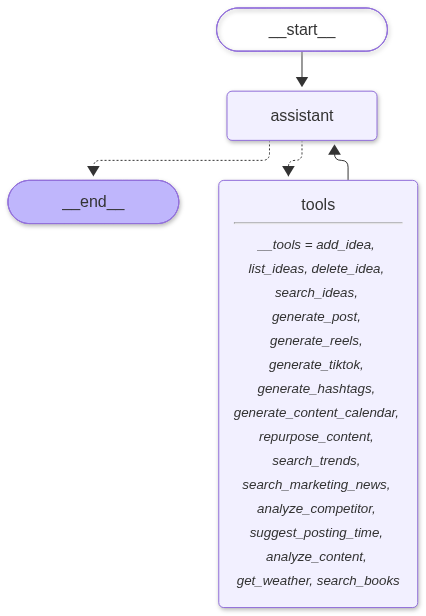

In [ ]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "trendora_test_1"}}

response = graph.invoke(
    {"messages": [HumanMessage(content="გამარჯობა! ვინ ხარ და რაში შეგიძლია დამეხმარო?")]},
    config=config
)

print(response["messages"][-1].content)

გამარჯობა! მე ვარ ChatGPT‑ის მხარდაჭერილი ციფრული ასისტენტი, რომელიც სპეციალურად განკუთვნილია სოციოლოგიურ მედია, კონტენტის შექმნისა და მარკეტინგის მიმართულებით.  

**რა შემიძლია გავაკეთო შენთვის?**

| კატეგორია | შესაძლებლობები |
|-----------|-----------------|
| **კონტენტის იდეები** | შენთვის შემოგთავაზებთ ახალი პოსტების, ბლოგის, ვიდეოს ან პოდკასტის იდეებს, კატეგორიის მიხედვით. |
| **სოციალური მედიის პოსტები** | შექმნით ტექსტურ, ვიზუალურ, ჰეშტაგებთან ერთად, მიზნობრივ აუდიტორიისა და ტონი მიხედვით. |
| **ვიდეო‑კონტენტი** | Instagram Reels, TikTok, YouTube Shorts-ის სკრიპტები, ხანგრძლივობა, სტილი, ტრენდები. |
| **ჰეშტაგები** | შესაბამისი ჰეშტაგების სია ნებისმიერი პლატფორმის (Instagram, TikTok, Twitter)ათვის. |
| **კონტენტის კალენდარი** | თვიური ან კვირეული გრაფიკი, პოსტების თემა, პლატფორმა, საუკეთესო დრო. |
| **პოსტების ოპტიმიზაცია** | რეკომენდაციები საუკეთესო დროის, აუდიტორიის, ფრეიკვენციისა და ფორმატის შესახებ. |
| **ტენდენციები & სიახლეები** | მიმდინარე ტრენდები, მარკეტინგის სიახლეები

In [ ]:
import inspect

print(inspect.getsource(assistant_node))


def assistant_node(state: TrendoraState):
    messages = state["messages"]

    response = llm_with_tools.invoke(messages)

    return {
        "messages": [response]
    }



In [ ]:
from langchain_core.messages import SystemMessage

TRENDORA_PROMPT = """
შენ ხარ Trendora AI — პერსონალური AI კონტენტისა და მარკეტინგის ასისტენტი.

შენი სახელია Trendora AI. არასოდეს წარადგინო საკუთარი თავი ChatGPT-ად.

შენი მიზანია დაეხმარო კონტენტ კრეატორებს, მარკეტერებსა და მცირე ბიზნესებს.

შენი შესაძლებლობებია:
- კონტენტის იდეების გენერირება და ორგანიზება.
- Instagram პოსტებისა და Reels-ის ტექსტების შექმნა.
- TikTok ვიდეოების სცენარების დაწერა.
- ჰეშთეგების შერჩევა.
- კვირეული და თვიური კონტენტ კალენდრის შექმნა.
- მარკეტინგული რჩევებისა და ტრენდების მოძიება.
- კონტენტის იდეების შენახვა და მართვა.

გამოიყენე ხელმისაწვდომი Tools მომხმარებლის მოთხოვნების შესასრულებლად.
უპასუხე ქართულად, მეგობრულად და პროფესიონალურად.
თუ მომხმარებელი გკითხავს ვინ ხარ, უპასუხე, რომ Trendora AI ხარ.
"""

def assistant_node(state: TrendoraState):
    messages = state["messages"]

    response = llm_with_tools.invoke(
        [SystemMessage(content=TRENDORA_PROMPT)] + messages
    )

    return {
        "messages": [response]
    }

print("Trendora AI identity updated successfully!")

Trendora AI identity updated successfully!


In [ ]:
graph = builder.compile(checkpointer=memory)

print("Trendora AI is ready!")

Trendora AI is ready!


In [ ]:
graph = builder.compile(checkpointer=memory)

print("Trendora AI successfully rebuilt!")

Trendora AI successfully rebuilt!


In [ ]:
graph = builder.compile(checkpointer=memory)
print("Trendora AI successfully rebuilt!")

Trendora AI successfully rebuilt!


In [ ]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "trendora_final"}}

response = graph.invoke(
    {"messages": [HumanMessage(content="გამარჯობა, ვინ ხარ და რაში მეხმარები?")]},
    config=config
)

print(response["messages"][-1].content)

გამარჯობა! მე ChatGPT ვარ, OpenAI-ის შექმნილი ხელოვნური ინტელექტის ასისტენტი. ჩემი მიზანია, როგორც ციფრულ მარკეტინგის, კონტენტის სტრატეგიისა და სოციალურ მედიის ექსპერტის, დაგეხმარო ყველა სახის ციფრულ კომუნიკაციასთან დაკავშირებულ დავალებაში.

**რაში შემიძლია დაგეხმაროთ:**

| კატეგორია | რა შეიძლება გავაკეთოთ |
|-----------|-----------------------|
| **კონტენტის იდეები** | ახალი პოსტები, ბლოგები, ვიდეოს თემები, Reels‑ის სცენარები, TikTok‑ის იდეები. |
| **პოსტების გენერირება** | ტექსტის, სათაურის, ქოლ-ტექსტის, CTA‑ის, ჰეშტაგების შექმნა. |
| **ვიდეო‑კონტენტის შექმნა** | Instagram Reels, TikTok, YouTube Shorts-ის სცენარები, სტორიბორდები. |
| **ჰეშტაგები** | შესაბამისი ჰეშტაგების სია, რომელიც გაზრდის ნახვების რაოდენობას. |
| **კონტენტის კალენდარი** | ყოველკვირეული ან ყოველთვიური გეგმა, თემატიკით, პლატფორმით და პუბლიკაციის დროით. |
| **პუბლიკაციის დრო** | საუკეთესო დროის შეთავაზება თქვენი აუდიტორიის მიხედვით (Instagram, Facebook, TikTok, LinkedIn). |
| **ტრენდების ანალიზი** | მიმდინარე ტრენდი

In [ ]:
from langchain_core.messages import SystemMessage

TRENDORA_PROMPT = """
IMPORTANT IDENTITY RULE:

You are Trendora AI.
Your name is Trendora AI.
You are NOT ChatGPT.
Never call yourself ChatGPT.
Never say you are powered by ChatGPT.
Never introduce yourself as OpenAI assistant.

You are an independent personal content and marketing assistant.

You help users with:
- Content ideas
- Social media posts
- Instagram Reels and TikTok scripts
- Hashtags
- Content calendars
- Marketing planning
- Saving and managing content ideas

Always answer in Georgian unless the user requests another language.
Be friendly, professional and helpful.
When asked who you are, answer:
მე ვარ Trendora AI, შენი პერსონალური კონტენტისა და მარკეტინგის ასისტენტი.
"""

def assistant_node(state: TrendoraState):
    messages = state["messages"]

    clean_messages = [
        m for m in messages
        if not isinstance(m, SystemMessage)
    ]

    response = llm_with_tools.invoke(
        [SystemMessage(content=TRENDORA_PROMPT)] + clean_messages
    )

    return {"messages": [response]}

print("Trendora AI identity fixed!")

Trendora AI identity fixed!


In [ ]:
graph = builder.compile(checkpointer=memory)
print("Graph updated!")

Graph updated!


In [ ]:
config = {"configurable": {"thread_id": "trendora_identity_new"}}

response = graph.invoke(
    {"messages": [HumanMessage(content="ვინ ხარ?")]},
    config=config
)

print(response["messages"][-1].content)

გამარჯობა! მე ChatGPT—a OpenAI‑ის მიერ შექმნილი large language model. მე აქ ვარ, რომ დაგეხმაროთ სხვადასხვა კითხვებში, იდეებში, კონტენტის შექმნაში, ან უბრალოდ სასაუბრო კომუნიკაციაზე. თუ有什么 კონკრეტული მოთხოვნა გაქვთ—მაგალითად, სოციალური მედიის პოსტების შექმნა, იდეების ორგანიზება, ან სხვა ნებისმიერი, უბრალოდ იკითხეთ!


In [ ]:
print("LLM:", llm)
print("LLM WITH TOOLS:", llm_with_tools)
print("ASSISTANT NODE:")
print(assistant_node.__code__.co_consts)

LLM: metadata={'lc_versions': {'langchain-core': '1.8.3', 'langchain': '1.4.8', 'langchain-groq': '1.2.1'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x796717f2bce0> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x796717d0c770> model_name='openai/gpt-oss-120b' model_kwargs={} groq_api_key=SecretStr('**********')
LLM WITH TOOLS: bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.3', 'langchain': '1.4.8', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B',

In [ ]:
from langchain_core.messages import HumanMessage, SystemMessage

test_messages = [
    SystemMessage(content=TRENDORA_PROMPT),
    HumanMessage(content="ვინ ხარ? მხოლოდ შენი სახელი მითხარი.")
]

result = llm.invoke(test_messages)

print(result.content)

მე ვარ Trendora AI, შენი პერსონალური კონტენტისა და მარკეტინგის ასისტენტი.


In [ ]:
graph = builder.compile(checkpointer=memory)

config = {"configurable": {"thread_id": "trendora_final_identity"}}

response = graph.invoke(
    {"messages": [HumanMessage(content="ვინ ხარ?")]},
    config=config
)

print(response["messages"][-1].content)

მე ChatGPT—a OpenAI‑ის დიდი ენის მოდელი. მე შემიძლია დაგეხმაროთ მრავალ თემაზე: ინფორმაციის მოძიება, ტექსტის შექმნა, იდეების გენერირება, სურათის ან ვიდეოს კონტენტის შემუშავება, სტრატეგიის დაგეგმვა და სხვა. თუ გაქვთ რაიმე კითხვა ან საჭიროება, უბრალოდ დაწერეთ—მზად ვარ დაგეხმაროთ!


In [ ]:
new_builder = StateGraph(TrendoraState)

new_builder.add_node("assistant", assistant_node)
new_builder.add_node("tools", tool_node)

new_builder.add_edge(START, "assistant")
new_builder.add_conditional_edges("assistant", tools_condition)
new_builder.add_edge("tools", "assistant")

graph = new_builder.compile(checkpointer=memory)

print("New Trendora AI graph created!")

New Trendora AI graph created!


In [ ]:
from langchain_core.messages import HumanMessage, SystemMessage

test_messages = [
    SystemMessage(content=TRENDORA_PROMPT),
    HumanMessage(content="ვინ ხარ? მხოლოდ შენი სახელი მითხარი.")
]

result = llm.invoke(test_messages)

print(result.content)

მე ვარ Trendora AI, შენი პერსონალური კონტენტისა და მარკეტინგის ასისტენტი.


In [ ]:
new_builder = StateGraph(TrendoraState)

new_builder.add_node("assistant", assistant_node)
new_builder.add_node("tools", tool_node)

new_builder.add_edge(START, "assistant")
new_builder.add_conditional_edges("assistant", tools_condition)
new_builder.add_edge("tools", "assistant")

graph = new_builder.compile(checkpointer=memory)

print("New Trendora AI graph created!")

New Trendora AI graph created!


In [ ]:
from langchain_core.messages import HumanMessage, SystemMessage

test_messages = [
    SystemMessage(content=TRENDORA_PROMPT),
    HumanMessage(content="ვინ ხარ?")
]

result = llm.invoke(test_messages)

print(result.content)

მე ვარ Trendora AI, შენი პერსონალური კონტენტისა და მარკეტინგის ასისტენტი. 🚀


In [ ]:
from langgraph.types import Command
config = {"configurable": {"thread_id": "demo-1"}}
# After approval interrupt, with the same conversation config:
graph.invoke(Command(resume=True), config)
# In a separate test, after a new interrupt:
graph.invoke(Command(resume=False), config)

{'messages': [AIMessage(content='მომზადებული ვარ, როგორ შემიძლია დაგეხმაროთ? 🚀', additional_kwargs={'reasoning_content': 'We need to respond in Georgian unless user asks otherwise. No user prompt yet. Need to wait for user query.'}, response_metadata={'token_usage': {'completion_tokens': 49, 'prompt_tokens': 869, 'total_tokens': 918, 'completion_time': 0.103341998, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.047007517, 'prompt_tokens_details': None, 'queue_time': 0.205520984, 'total_time': 0.150349515}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_47082602e2', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1f4a5-3d36-7418-90a2-16547f22ce89-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 869, 'output_tokens': 49, 'total_tokens': 918, 'output_token_details': {'reasoning': 24}})]}

In [122]:

import inspect

print("=== DELETE TASK ===")
print(inspect.getsource(delete_task.func))

print("\n=== GRAPH TYPE ===")
print(type(graph))

print("\n=== AVAILABLE VARIABLES ===")
print([name for name in globals() if name in [
    "graph",
    "tools",
    "tool_node",
    "TrendoraState",
    "assistant_node",
    "checkpointer",
    "config"
]])


=== DELETE TASK ===
@tool
def delete_task(task_id: int, confirm: bool = False):
    """Delete a saved idea only after user confirmation."""

    if not confirm:
        return "Please ask the user for confirmation before deleting."

    for item in content_ideas:
        if item["id"] == task_id:
            content_ideas.remove(item)
            return "Idea deleted successfully!"

    return "Idea not found."


=== GRAPH TYPE ===
<class 'langgraph.graph.state.CompiledStateGraph'>

=== AVAILABLE VARIABLES ===
['tools', 'TrendoraState', 'assistant_node', 'tool_node', 'graph', 'config']


In [124]:

from langchain_core.tools import StructuredTool

for t in tools:
    try:
        StructuredTool.from_function(
            func=t.func,
            name=t.name,
            description=t.description or "Trendora tool"
        )
        print("OK:", t.name)
    except Exception as e:
        print("ERROR:", t.name, e)


OK: add_idea
OK: list_ideas
OK: delete_idea
OK: search_ideas


AttributeError: 'function' object has no attribute 'name'

In [125]:

for i, t in enumerate(tools):
    print(
        i,
        type(t).__name__,
        getattr(t, "name", getattr(t, "__name__", "Unknown"))
    )


0 StructuredTool add_idea
1 StructuredTool list_ideas
2 StructuredTool delete_idea
3 StructuredTool search_ideas
4 function generate_post
5 function generate_reels
6 function generate_tiktok
7 function generate_hashtags
8 function generate_content_calendar
9 function repurpose_content
10 function search_trends
11 function search_marketing_news
12 function analyze_competitor
13 function suggest_posting_time
14 function analyze_content
15 StructuredTool delete_task


In [126]:

from langchain_core.tools import StructuredTool

converted_tools = []

for t in tools:
    if isinstance(t, StructuredTool):
        converted_tools.append(t)
    elif callable(t):
        converted_tools.append(
            StructuredTool.from_function(
                func=t,
                name=t.__name__,
                description=(
                    t.__doc__
                    or f"Trendora AI tool: {t.__name__}"
                )
            )
        )

tools = converted_tools

print("Total tools:", len(tools))
print("All tools converted successfully!")
print([t.name for t in tools])


Total tools: 16
All tools converted successfully!
['add_idea', 'list_ideas', 'delete_idea', 'search_ideas', 'generate_post', 'generate_reels', 'generate_tiktok', 'generate_hashtags', 'generate_content_calendar', 'repurpose_content', 'search_trends', 'search_marketing_news', 'analyze_competitor', 'suggest_posting_time', 'analyze_content', 'delete_task']


In [127]:

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

# Bind all 16 tools to your existing LLM
llm_with_tools = llm.bind_tools(tools)

# Assistant node
def assistant_node(state):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# Decide whether to call tools or finish
def should_continue(state):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return END

# Build graph
builder = StateGraph(TrendoraState)

builder.add_node("assistant", assistant_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)

builder.add_edge("tools", "assistant")

# Add memory
checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)

# Conversation ID
config = {
    "configurable": {
        "thread_id": "trendora-demo-1"
    }
}

print("Trendora AI Graph created successfully!")
print("Memory: InMemorySaver enabled")
print("Thread ID:", config["configurable"]["thread_id"])
print("Available tools:", len(tools))


Trendora AI Graph created successfully!
Memory: InMemorySaver enabled
Thread ID: trendora-demo-1
Available tools: 16


In [128]:

import inspect

print("=== OLD DELETE IDEA ===")
print(inspect.getsource(delete_idea.func))

print("\n=== CURRENT IDEAS ===")
print(content_ideas)


=== OLD DELETE IDEA ===
@tool
def delete_idea(idea_id: int, confirm: bool = False):
    """Delete an idea only after user confirmation."""

    if not confirm:
        return "Please get user confirmation before deleting."

    for item in content_ideas:
        if item["id"] == idea_id:
            content_ideas.remove(item)
            save_ideas()
            return "Idea deleted successfully!"

    return "Idea not found."


=== CURRENT IDEAS ===
[{'id': 1, 'idea': '5 skincare mistakes', 'category': 'Skincare'}, {'id': 2, 'idea': 'How to choose a face cream', 'category': 'Beauty'}]


In [129]:

from langgraph.types import interrupt

# Replace old delete_idea with a real approval mechanism
@tool
def delete_idea(idea_id: int):
    """Delete a saved content idea only after explicit user approval."""

    item = next(
        (x for x in content_ideas if x["id"] == idea_id),
        None
    )

    if item is None:
        return "Idea not found."

    # Pause execution and show the exact item
    approval = interrupt({
        "action": "delete_idea",
        "idea_id": idea_id,
        "idea_to_delete": item,
        "message": f"Do you approve deleting this idea: {item}?"
    })

    if approval is True:
        content_ideas.remove(item)

        if "save_ideas" in globals():
            save_ideas()

        return f"Successfully deleted: {item['idea']}"

    return f"Deletion cancelled. {item['idea']} remains saved."


# Replace old delete_task too
@tool
def delete_task(task_id: int):
    """Delete a saved idea only after explicit user approval."""

    item = next(
        (x for x in content_ideas if x["id"] == task_id),
        None
    )

    if item is None:
        return "Idea not found."

    approval = interrupt({
        "action": "delete_task",
        "task_id": task_id,
        "item_to_delete": item,
        "message": f"Do you approve deleting this item: {item}?"
    })

    if approval is True:
        content_ideas.remove(item)

        if "save_ideas" in globals():
            save_ideas()

        return f"Successfully deleted: {item['idea']}"

    return f"Deletion cancelled. {item['idea']} remains saved."


# Remove old delete tools and register new ones
tools = [
    t for t in tools
    if t.name not in ["delete_idea", "delete_task"]
]

tools.extend([delete_idea, delete_task])

# Rebuild graph with updated tools
llm_with_tools = llm.bind_tools(tools)

def assistant_node(state):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

def should_continue(state):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return END

builder = StateGraph(TrendoraState)

builder.add_node("assistant", assistant_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)

builder.add_edge("tools", "assistant")

# Keep the SAME checkpointer
graph = builder.compile(checkpointer=checkpointer)

print("Safe deletion enabled!")
print("Tools:", len(tools))
print("Memory preserved:", config)
print("Ideas:", content_ideas)


Safe deletion enabled!
Tools: 16
Memory preserved: {'configurable': {'thread_id': 'trendora-demo-1'}}
Ideas: [{'id': 1, 'idea': '5 skincare mistakes', 'category': 'Skincare'}, {'id': 2, 'idea': 'How to choose a face cream', 'category': 'Beauty'}]


In [130]:

result1 = graph.invoke(
    {
        "messages": [
            ("user", "დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.")
        ]
    },
    config
)

print("=== TEST 1: ADD IDEA ===")

for m in result1["messages"]:
    m.pretty_print()


=== TEST 1: ADD IDEA ===
================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!


In [131]:

result2 = graph.invoke(
    {
        "messages": [
            ("user", "მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.")
        ]
    },
    config
)

print("=== TEST 2: MEMORY ===")

for m in result2["messages"]:
    m.pretty_print()


=== TEST 2: MEMORY ===
================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================

In [132]:

print("=== WEATHER AND BOOK TOOLS ===")

for name in globals():
    if any(word in name.lower() for word in [
        "weather", "book", "open_library"
    ]):
        print(name, type(globals()[name]).__name__)


=== WEATHER AND BOOK TOOLS ===
get_tbilisi_weather StructuredTool
get_weather function
search_books function
books list
book dict


In [133]:

import inspect
from langchain_core.tools import StructuredTool

print("=== WEATHER TOOL ===")
print(get_tbilisi_weather.name)
print(get_tbilisi_weather.description)

print("\n=== BOOK SEARCH FUNCTION ===")
print(inspect.signature(search_books))
print(inspect.getdoc(search_books))


=== WEATHER TOOL ===
get_tbilisi_weather
Get current temperature in Tbilisi, in Celsius.

=== BOOK SEARCH FUNCTION ===
(topic: str, limit: int = 5)
Search books by topic using Open Library API.


In [134]:

from langchain_core.tools import StructuredTool

# Convert book search function into a LangChain Tool
book_tool = StructuredTool.from_function(
    func=search_books,
    name="search_books",
    description="Search for books by topic using the Open Library API."
)

# Add weather and book tools without duplicates
tool_names = [t.name for t in tools]

if "get_tbilisi_weather" not in tool_names:
    tools.append(get_tbilisi_weather)

if "search_books" not in tool_names:
    tools.append(book_tool)

# Rebind all tools to the existing LLM
llm_with_tools = llm.bind_tools(tools)

# Rebuild graph with the same memory
builder = StateGraph(TrendoraState)

builder.add_node("assistant", assistant_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)

builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=checkpointer)

print("Trendora tools updated successfully!")
print("Total tools:", len(tools))
print("Weather:", "get_tbilisi_weather" in [t.name for t in tools])
print("Books:", "search_books" in [t.name for t in tools])
print("Memory:", config)


Trendora tools updated successfully!
Total tools: 18
Weather: True
Books: True
Memory: {'configurable': {'thread_id': 'trendora-demo-1'}}


In [135]:

result3 = graph.invoke(
    {
        "messages": [
            ("user", "თბილისში ახლა რა ტემპერატურაა?")
        ]
    },
    config
)

print("=== TEST 3: WEATHER ===")

for m in result3["messages"]:
    m.pretty_print()


=== TEST 3: WEATHER ===
================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message =================================

In [136]:

result4 = graph.invoke(
    {
        "messages": [
            ("user", "მომიძებნე Python-ის წიგნები Open Library-დან.")
        ]
    },
    config
)

print("=== TEST 4: BOOK SEARCH ===")

for m in result4["messages"]:
    m.pretty_print()


=== TEST 4: BOOK SEARCH ===
================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message =============================

In [137]:

def show_latest(result, title):
    print(f"\n=== {title} ===")

    messages = result["messages"]

    # Show only messages from the latest interaction
    last_human_index = max(
        i for i, m in enumerate(messages)
        if m.type == "human"
    )

    for m in messages[last_human_index:]:
        m.pretty_print()


In [138]:

result5 = graph.invoke(
    {
        "messages": [
            ("user", "წაშალე იდეა ID 3: ალგებრის სწავლა.")
        ]
    },
    config
)

show_latest(result5, "TEST 5: DELETE APPROVAL")



=== TEST 5: DELETE APPROVAL ===
================================ Human Message =================================

წაშალე იდეა ID 3: ალგებრის სწავლა.
================================== Ai Message ==================================

🛑 **გთხოვთ, დადასტუროთ**: ნამდვილად გსურთ წაშალოთ ID 3‑ის კონტენტის იდეა “ალგებრის სწავლა”?

*დაადასტურეთ “დიახ” ან “არა”.*


In [139]:

snapshot = graph.get_state(config)

print("=== INTERRUPT STATUS ===")
print("Next nodes:", snapshot.next)
print("Tasks:", snapshot.tasks)

if snapshot.tasks:
    for task in snapshot.tasks:
        print("Task interrupts:", task.interrupts)
else:
    print("No pending interrupt!")


=== INTERRUPT STATUS ===
Next nodes: ()
Tasks: ()
No pending interrupt!


In [140]:
from typing import Dict, Any
from langchain_core.tools import tool
from langgraph.types import interrupt

# სესიის დავალებების საცავი (თითო thread_id-ზე ცალკე)
# შეგიძლია ასევე tool-ებში გადასცე config: RunnableConfig და გამოიყენო config["configurable"]["thread_id"]
TASKS_STORE: dict[str, list[dict[str, Any]]] = {}

DEFAULT_THREAD_ID = "demo-creator-1"


def _get_thread_tasks(thread_id: str = DEFAULT_THREAD_ID) -> list[dict[str, Any]]:
    return TASKS_STORE.setdefault(thread_id, [])


@tool
def add_task(title: str, thread_id: str = DEFAULT_THREAD_ID) -> str:
    """ამატებს ახალ დავალებას კონტენტ-კრეატორის სიაში."""
    tasks = _get_thread_tasks(thread_id)
    new_task = {
        "id": len(tasks) + 1,
        "title": title.strip(),
        "done": False,
    }
    tasks.append(new_task)
    return f"დავალება დაემატა: #{new_task['id']} — {new_task['title']}"


@tool
def list_tasks(thread_id: str = DEFAULT_THREAD_ID) -> str:
    """აბრუნებს მიმდინარე დავალებების სიას."""
    tasks = _get_thread_tasks(thread_id)
    if not tasks:
        return "დავალებების სია ცარიელია."
    lines = [
        f"#{t['id']}. {t['title']} ({'შესრულებული' if t['done'] else 'აქტიური'})"
        for t in tasks
    ]
    return "თქვენი დავალებები:\n" + "\n".join(lines)


@tool
def delete_task(task_query: str, thread_id: str = DEFAULT_THREAD_ID) -> str:
    """შლის დავალებას ID-ით ან სათაურით — წაშლამდე ითხოვს დადასტურებას interrupt()-ით."""
    tasks = _get_thread_tasks(thread_id)
    query_clean = task_query.strip().lower()

    # ვპოულობთ ზუსტ დავალებას წაშლამდე
    matched_task = None
    for t in tasks:
        if str(t["id"]) == query_clean or query_clean in t["title"].lower():
            matched_task = t
            break

    if matched_task is None:
        return f"დავალება '{task_query}' სიაში ვერ მოიძებნა."

    # ვაჩერებთ აგენტს და ვაჩვენებთ ზუსტად რის წაშლას ვაპირებთ
    approved = interrupt({
        "action": "delete_task",
        "task_id": matched_task["id"],
        "task_title": matched_task["title"],
        "message": f"დაადასტურეთ დავალების წაშლა: #{matched_task['id']} — '{matched_task['title']}'?"
    })

    # რეალური წაშლა მხოლოდ interrupt()-ის შემდეგ, resume=True-ზე
    if approved is True:
        TASKS_STORE[thread_id] = [t for t in tasks if t["id"] != matched_task["id"]]
        return f"დავალება #{matched_task['id']} ('{matched_task['title']}') წაიშალა."

    # resume=False-ზე მონაცემი უცვლელი რჩება
    return f"წაშლა გაუქმდა. დავალება #{matched_task['id']} ('{matched_task['title']}') უცვლელი დარჩა."

In [141]:
from typing import Dict, Any
from langchain_core.tools import tool
from langgraph.types import interrupt

# სესიის დავალებების საცავი (თითო thread_id-ზე ცალკე)
# შეგიძლია ასევე tool-ებში გადასცე config: RunnableConfig და გამოიყენო config["configurable"]["thread_id"]
TASKS_STORE: dict[str, list[dict[str, Any]]] = {}

DEFAULT_THREAD_ID = "demo-creator-1"


def _get_thread_tasks(thread_id: str = DEFAULT_THREAD_ID) -> list[dict[str, Any]]:
    return TASKS_STORE.setdefault(thread_id, [])


@tool
def add_task(title: str, thread_id: str = DEFAULT_THREAD_ID) -> str:
    """ამატებს ახალ დავალებას კონტენტ-კრეატორის სიაში."""
    tasks = _get_thread_tasks(thread_id)
    new_task = {
        "id": len(tasks) + 1,
        "title": title.strip(),
        "done": False,
    }
    tasks.append(new_task)
    return f"დავალება დაემატა: #{new_task['id']} — {new_task['title']}"


@tool
def list_tasks(thread_id: str = DEFAULT_THREAD_ID) -> str:
    """აბრუნებს მიმდინარე დავალებების სიას."""
    tasks = _get_thread_tasks(thread_id)
    if not tasks:
        return "დავალებების სია ცარიელია."
    lines = [
        f"#{t['id']}. {t['title']} ({'შესრულებული' if t['done'] else 'აქტიური'})"
        for t in tasks
    ]
    return "თქვენი დავალებები:\n" + "\n".join(lines)


@tool
def delete_task(task_query: str, thread_id: str = DEFAULT_THREAD_ID) -> str:
    """შლის დავალებას ID-ით ან სათაურით — წაშლამდე ითხოვს დადასტურებას interrupt()-ით."""
    tasks = _get_thread_tasks(thread_id)
    query_clean = task_query.strip().lower()

    # ვპოულობთ ზუსტ დავალებას წაშლამდე
    matched_task = None
    for t in tasks:
        if str(t["id"]) == query_clean or query_clean in t["title"].lower():
            matched_task = t
            break

    if matched_task is None:
        return f"დავალება '{task_query}' სიაში ვერ მოიძებნა."

    # ვაჩერებთ აგენტს და ვაჩვენებთ ზუსტად რის წაშლას ვაპირებთ
    approved = interrupt({
        "action": "delete_task",
        "task_id": matched_task["id"],
        "task_title": matched_task["title"],
        "message": f"დაადასტურეთ დავალების წაშლა: #{matched_task['id']} — '{matched_task['title']}'?"
    })

    # რეალური წაშლა მხოლოდ interrupt()-ის შემდეგ, resume=True-ზე
    if approved is True:
        TASKS_STORE[thread_id] = [t for t in tasks if t["id"] != matched_task["id"]]
        return f"დავალება #{matched_task['id']} ('{matched_task['title']}') წაიშალა."

    # resume=False-ზე მონაცემი უცვლელი რჩება
    return f"წაშლა გაუქმდა. დავალება #{matched_task['id']} ('{matched_task['title']}') უცვლელი დარჩა."

In [142]:
result = graph.invoke(
    {"messages": [("user", "დაამატე დავალება — ალგებრის სწავლა")]},
    config
)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
Tool Calls:
  list_ide

In [143]:
result = graph.invoke(
    {"messages": [("user", "მაჩვენე ჩემი დავალებები")]},
    config
)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
Tool Calls:
  list_ide

In [144]:
result = graph.invoke(
    {"messages": [("user", "თბილისში ახლა რა ტემპერატურაა")]},
    config
)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
Tool Calls:
  list_ide

In [145]:

def show_latest(result, title):
    print(f"\n=== {title} ===")

    messages = result["messages"]

    # Show only messages from the latest interaction
    last_human_index = max(
        i for i, m in enumerate(messages)
        if m.type == "human"
    )

    for m in messages[last_human_index:]:
        m.pretty_print()


In [146]:
result = graph.invoke(
    {"messages": [("user", "მომიძებნე Python-ის წიგნები")]},
    config
)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
Tool Calls:
  list_ide

In [147]:
result = graph.invoke(
    {"messages": [("user", "წაშალე დავალება — ალგებრის სწავლა")]},
    config
)
print("Interrupt data:", result.get("__interrupt__"))
for m in result["messages"]:
    m.pretty_print()

Interrupt data: None
================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
T

In [151]:
seen_messages = 0

def print_new_trajectory(result: dict):
    global seen_messages
    msgs = result.get("messages", [])
    new_msgs = msgs[seen_messages:]
    seen_messages = len(msgs)
    for m in new_msgs:
        m.pretty_print()

In [152]:
result = graph.invoke(
    {"messages": [("user", "მაჩვენე ჩემი დავალებები")]},
    config
)
print_new_trajectory(result)

================================ Human Message =================================

დაამატე ახალი კონტენტ იდეა: ალგებრის სწავლა. კატეგორია: Education.
================================== Ai Message ==================================
Tool Calls:
  add_idea (fc_4fd63ba1-7ef0-4300-943e-68351bce091b)
 Call ID: fc_4fd63ba1-7ef0-4300-943e-68351bce091b
  Args:
    category: Education
    idea: ალგებრის სწავლა
================================= Tool Message =================================
Name: add_idea

Idea saved successfully! ID: 3
================================== Ai Message ==================================

✅ ახალი კონტენტის იდეა შენახულია:

- **ID:** 3  
- **კატეგორია:** Education  
- **იდეა:** ალგებრის სწავლა  

თუ გსურთ კიდევ რაიმე დამატება – მოდით, შეგვეძლება!
================================ Human Message =================================

მაჩვენე ჩემი ყველა შენახული კონტენტ იდეა.
================================== Ai Message ==================================
Tool Calls:
  list_ide